**Submitted by:** Ansh Upadhyay

In [1]:
import math, random, re, warnings
from collections import Counter
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from datasets import load_dataset
from sacrebleu.metrics import BLEU

warnings.filterwarnings("ignore")
SEED = 17
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EMB_DIM, HIDDEN_DIM, BATCH_SIZE = 128, 256, 64
print("device:", device)

device: cuda


In [2]:
raw = load_dataset("bentrevett/multi30k")
train_pairs = [(r["de"], r["en"]) for r in raw["train"]]
random.Random(SEED).shuffle(train_pairs)
train_pairs = train_pairs[:12000]

# remove valid/test sentences whose German source is already in training
seen = {s.lower() for s, _ in train_pairs}
valid_pairs = [(r["de"], r["en"]) for r in raw["validation"] if r["de"].lower() not in seen]
test_pairs = [(r["de"], r["en"]) for r in raw["test"] if r["de"].lower() not in seen]
print("train / valid / test:", len(train_pairs), len(valid_pairs), len(test_pairs))

PAD, UNK, SOS, EOS = 0, 1, 2, 3

def tokenize(text):
    return re.findall(r"[^\W_]+|[^\w\s]", text.lower())   # words and punctuation

def build_vocab(texts, min_freq=2):
    counts = Counter(tok for t in texts for tok in tokenize(t))
    vocab = {"<pad>": 0, "<unk>": 1, "<sos>": 2, "<eos>": 3}
    for tok, freq in counts.most_common(6000 - 4):
        if freq >= min_freq:
            vocab[tok] = len(vocab)
    return vocab

src_vocab = build_vocab([s for s, _ in train_pairs])
tgt_vocab = build_vocab([t for _, t in train_pairs])
tgt_itos = {i: tok for tok, i in tgt_vocab.items()}
print("German vocab:", len(src_vocab), "| English vocab:", len(tgt_vocab))

def to_ids(text, vocab):
    return [SOS] + [vocab.get(tok, UNK) for tok in tokenize(text)] + [EOS]

def collate(batch):
    src = [torch.tensor(to_ids(s, src_vocab)) for s, _ in batch]
    tgt = [torch.tensor(to_ids(t, tgt_vocab)) for _, t in batch]
    lengths = torch.tensor([len(s) for s in src])
    return pad_sequence(src, True, PAD), lengths, pad_sequence(tgt, True, PAD)

train_loader = DataLoader(train_pairs, BATCH_SIZE, shuffle=True, collate_fn=collate)
valid_loader = DataLoader(valid_pairs, BATCH_SIZE, collate_fn=collate)

train / valid / test: 12000 1012 1000
German vocab: 4469 | English vocab: 3819


In [3]:
class Encoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMB_DIM, padding_idx=PAD)
        self.lstm = nn.LSTM(EMB_DIM, HIDDEN_DIM, batch_first=True)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(self.embedding(src), lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, (hidden, cell) = self.lstm(packed)                      # LSTM skips <pad>
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        return out, (hidden, cell)                                   # (B,Tx,H), (1,B,H)


class ConcatAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.alignment = nn.Linear(2 * HIDDEN_DIM, HIDDEN_DIM)       # W_a
        self.score = nn.Linear(HIDDEN_DIM, 1, bias=False)            # v_a

    def forward(self, query, enc_out, src_mask):
        query = query.unsqueeze(1).repeat(1, enc_out.size(1), 1)     # (B,Tx,H)
        energy = torch.tanh(self.alignment(torch.cat([query, enc_out], dim=-1)))
        scores = self.score(energy).squeeze(-1)                      # (B,Tx)
        scores = scores.masked_fill(~src_mask, -1e10)                # ignore <pad>
        weights = torch.softmax(scores, dim=1)                       # (B,Tx), rows sum to 1
        context = torch.bmm(weights.unsqueeze(1), enc_out).squeeze(1)  # (B,H)
        return context, weights


class Decoder(nn.Module):
    def __init__(self, vocab_size, use_attention):
        super().__init__()
        self.attention = ConcatAttention() if use_attention else None
        ctx = HIDDEN_DIM if use_attention else 0
        self.embedding = nn.Embedding(vocab_size, EMB_DIM, padding_idx=PAD)
        self.lstm = nn.LSTM(EMB_DIM + ctx, HIDDEN_DIM, batch_first=True)
        self.fc_out = nn.Linear(HIDDEN_DIM + ctx, vocab_size)

    def forward(self, prev_token, hidden, cell, enc_out, src_mask):
        x = self.embedding(prev_token).unsqueeze(1)                  # (B,1,E)
        weights = None
        if self.attention:
            context, weights = self.attention(hidden[-1], enc_out, src_mask)
            x = torch.cat([x, context.unsqueeze(1)], dim=-1)
        out, (hidden, cell) = self.lstm(x, (hidden, cell))
        out = out.squeeze(1)
        if self.attention:
            out = torch.cat([out, context], dim=-1)
        return self.fc_out(out), hidden, cell, weights               # logits (B,V)


class Seq2Seq(nn.Module):
    def __init__(self, use_attention):
        super().__init__()
        self.encoder = Encoder(len(src_vocab))
        self.decoder = Decoder(len(tgt_vocab), use_attention)

    def forward(self, src, lengths, tgt, teacher_forcing=0.5):
        enc_out, (hidden, cell) = self.encoder(src, lengths)
        mask = src.ne(PAD)
        prev, all_logits = tgt[:, 0], []                             # start with <sos>
        for t in range(1, tgt.size(1)):
            logits, hidden, cell, _ = self.decoder(prev, hidden, cell, enc_out, mask)
            all_logits.append(logits)
            prev = tgt[:, t] if random.random() < teacher_forcing else logits.argmax(-1)
        return torch.stack(all_logits, dim=1)                        # (B,Ty-1,V)

criterion = nn.CrossEntropyLoss(ignore_index=PAD)

In [4]:
model = Seq2Seq(use_attention=True).to(device)
src, lengths, tgt = (x.to(device) for x in next(iter(train_loader)))
enc_out, (hidden, cell) = model.encoder(src, lengths)
mask = src.ne(PAD)
context, weights = model.decoder.attention(hidden[-1], enc_out, mask)

assert weights.shape == src.shape and context.shape == (src.size(0), HIDDEN_DIM)
assert torch.allclose(weights.sum(1), torch.ones(src.size(0), device=device))
assert torch.all(weights[~mask] < 1e-6)

loss = criterion(model(src, lengths, tgt, 1.0).flatten(0, 1), tgt[:, 1:].flatten())
loss.backward()
assert model.decoder.attention.alignment.weight.grad is not None
assert model.encoder.lstm.weight_ih_l0.grad is not None
print("All attention checks passed")

All attention checks passed


Baseline


epoch 1: train 5.039 | valid 4.293


epoch 2: train 4.383 | valid 3.877


epoch 3: train 4.068 | valid 3.563


epoch 4: train 3.832 | valid 3.356


...

epoch 4: train 3.024 | valid 2.665


epoch 5: train 2.729 | valid 2.517


epoch 6: train 2.500 | valid 2.422


epoch 7: train 2.273 | valid 2.357


epoch 8: train 2.090 | valid 2.319
parameters: 2832875 vs 4204267


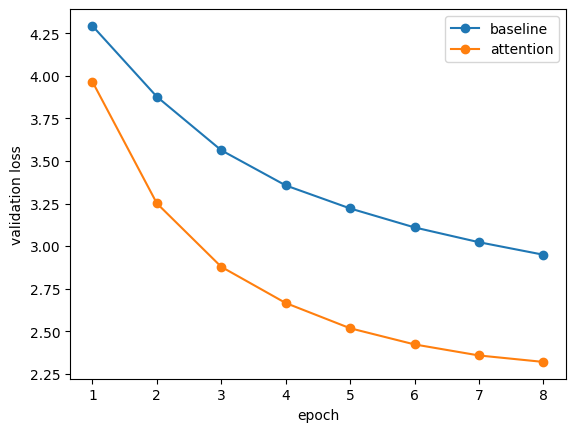

In [5]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_tokens = 0.0, 0
    for src, lengths, tgt in loader:
        src, lengths, tgt = src.to(device), lengths.to(device), tgt.to(device)
        with torch.set_grad_enabled(training):
            logits = model(src, lengths, tgt, 0.5 if training else 1.0)
            loss = criterion(logits.flatten(0, 1), tgt[:, 1:].flatten())
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        n = tgt[:, 1:].ne(PAD).sum().item()
        total_loss += loss.item() * n
        total_tokens += n
    return total_loss / total_tokens


def train_model(use_attention, epochs=8):
    torch.manual_seed(SEED)
    random.seed(SEED)
    model = Seq2Seq(use_attention).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history, best_loss, best_state = [], float("inf"), None
    for epoch in range(1, epochs + 1):
        train_loss = run_epoch(model, train_loader, optimizer)
        valid_loss = run_epoch(model, valid_loader)
        history.append(valid_loss)
        print(f"epoch {epoch}: train {train_loss:.3f} | valid {valid_loss:.3f}")
        if valid_loss < best_loss:                                   # keep best weights
            best_loss = valid_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, history


print("Baseline");  baseline, base_hist = train_model(False)
print("Attention"); attention_model, att_hist = train_model(True)
print("parameters:", sum(p.numel() for p in baseline.parameters()),
      "vs", sum(p.numel() for p in attention_model.parameters()))

plt.plot(range(1, len(base_hist) + 1), base_hist, "o-", label="baseline")
plt.plot(range(1, len(att_hist) + 1), att_hist, "o-", label="attention")
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.legend(); plt.show()

In [6]:
def encode(model, text):
    ids = to_ids(text, src_vocab)
    src = torch.tensor([ids], device=device)
    enc_out, (hidden, cell) = model.encoder(src, torch.tensor([len(ids)]))
    return enc_out, hidden, cell, src.ne(PAD)


@torch.no_grad()
def greedy_translate(model, text, max_steps=40):
    model.eval()
    enc_out, hidden, cell, mask = encode(model, text)
    prev, words, rows = torch.tensor([SOS], device=device), [], []
    for _ in range(max_steps):
        logits, hidden, cell, weights = model.decoder(prev, hidden, cell, enc_out, mask)
        prev = logits.argmax(-1)                                     # best next word
        if prev.item() == EOS:
            break
        words.append(tgt_itos[prev.item()])
        if weights is not None:
            rows.append(weights[0].cpu())
    return words, (torch.stack(rows) if rows else None)


@torch.no_grad()
def beam_translate(model, text, beam_width=3, max_steps=40, alpha=0.6):
    model.eval()
    enc_out, hidden, cell, mask = encode(model, text)
    rank = lambda b: b[1] / ((5 + len(b[0]) - 1) / 6) ** alpha        # length-normalised score
    beams = [([SOS], 0.0, hidden, cell, False)]                      # tokens, log-prob, h, c, ended
    for _ in range(max_steps):
        candidates = []
        for tokens, score, h, c, ended in beams:
            if ended:
                candidates.append((tokens, score, h, c, True))
                continue
            logits, h2, c2, _ = model.decoder(torch.tensor([tokens[-1]], device=device), h, c, enc_out, mask)
            top_lp, top_ids = torch.log_softmax(logits, -1)[0].topk(beam_width)
            for lp, idx in zip(top_lp.tolist(), top_ids.tolist()):
                candidates.append((tokens + [idx], score + lp, h2, c2, idx == EOS))
        beams = sorted(candidates, key=rank, reverse=True)[:beam_width]
        if all(b[4] for b in beams):
            break
    best = max(beams, key=rank)[0]
    return [tgt_itos[t] for t in best[1:] if t != EOS]


# check: beam width 1 == greedy
for m in [baseline, attention_model]:
    for text, _ in valid_pairs[:20]:
        assert beam_translate(m, text, beam_width=1, max_steps=10) == greedy_translate(m, text, 10)[0]
print("Beam width 1 matches greedy")

Beam width 1 matches greedy


In [7]:
eval_pairs = random.Random(SEED).sample(test_pairs, 200)
references = [" ".join(tokenize(en)) for _, en in eval_pairs]
outputs = {}

print(f"{'model':<10}{'decoding':<9}{'perplexity':>11}{'BLEU':>8}")
for name, m in [("baseline", baseline), ("attention", attention_model)]:
    perplexity = math.exp(run_epoch(m, DataLoader(eval_pairs, BATCH_SIZE, collate_fn=collate)))
    for method in ["greedy", "beam"]:
        translate = (lambda t: greedy_translate(m, t)[0]) if method == "greedy" else (lambda t: beam_translate(m, t))
        hyps = [" ".join(translate(de)) for de, _ in eval_pairs]
        outputs[(name, method)] = hyps
        bleu = BLEU(force=True).corpus_score(hyps, [references]).score
        print(f"{name:<10}{method:<9}{perplexity:>11.2f}{bleu:>8.2f}")

model     decoding  perplexity    BLEU


baseline  greedy         17.97   10.87


baseline  beam           17.97   11.88


attention greedy          9.70   24.92


attention beam            9.70   27.60


In [8]:
lens = [len(tokenize(de)) for de, _ in eval_pairs]
att = outputs[("attention", "greedy")]
examples = {"SHORT": lens.index(min(lens)), "LONG": lens.index(max(lens)),
            "FAILURE": next(i for i in range(len(att)) if att[i] != references[i])}
for label, i in examples.items():
    print(f"\n--- {label} ---\nGerman   : {eval_pairs[i][0]}\nReference: {references[i]}")
    for key, hyps in outputs.items():
        print(f"{key[0]:<9} {key[1]:<6}: {hyps[i]}")


--- SHORT ---
German   : Ein Armeeoffizier inspiziert etwas.
Reference: an army officer is inspecting something .
baseline  greedy: a <unk> is is at the . .
baseline  beam  : a <unk> is <unk> .
attention greedy: a <unk> is is at something .
attention beam  : a <unk> is at something .

--- LONG ---
German   : Ein hell gekleideter Mann fotografiert eine Gruppe von Männern in dunklen Anzügen und mit Hüten, die um eine Frau in einem trägerlosen Kleid herum stehen.
Reference: a man in light colored clothing photographs a group of men wearing dark suits and hats standing around a woman dressed in a strapless gown .
baseline  greedy: a man is a a woman with a woman and a , and a , and a in a , and a in a in a white shirt .
baseline  beam  : a man is a a man with a woman and a woman in a , and , and a in in a white and white shirt .
attention greedy: an man is a a group of men men in a , , and a in a dress dress dress .
attention beam  : an man is taking a group of men men in a dark , and a i

**Exercise 5.**

| Model | Decoding | Perplexity | BLEU |
|---|---|---|---|
| Baseline | greedy / beam | 17.97 | 10.87 / 11.88 |
| Attention | greedy / beam | 9.70 | 24.92 / 27.60 |

- **Attention helps in this run:** perplexity drops from 17.97 to 9.70 and BLEU goes from about 11 to about 25–28, with identical data, settings and seed. (Caveat: attention has about 1.4M more parameters, and this is a single run.)
- **Perplexity is the same for greedy and beam** because it only scores the *reference* words and nothing is generated. BLEU scores the *generated* sentence, so the search method changes it. Beam adds about 1–3 BLEU here.
- **Lower perplexity does not always mean higher BLEU.** Perplexity is measured with teacher forcing, while BLEU uses free generation, where one early mistake spreads. BLEU also penalises valid synonyms ("older" vs "elderly").
- **Examples:** in the *short* one, the rare word "Armeeoffizier" becomes `<unk>` for both models. In the *long* one, the baseline loses the meaning, and attention recovers "group of men" but repeats "dress dress dress". In the *failure*, attention repeats "sitting" and translates "ein paar" (some) literally as "a pair".

## 7. Attention maps

Zwei Männer sitzen in einem Restaurant. -> two men sitting in a restaurant .


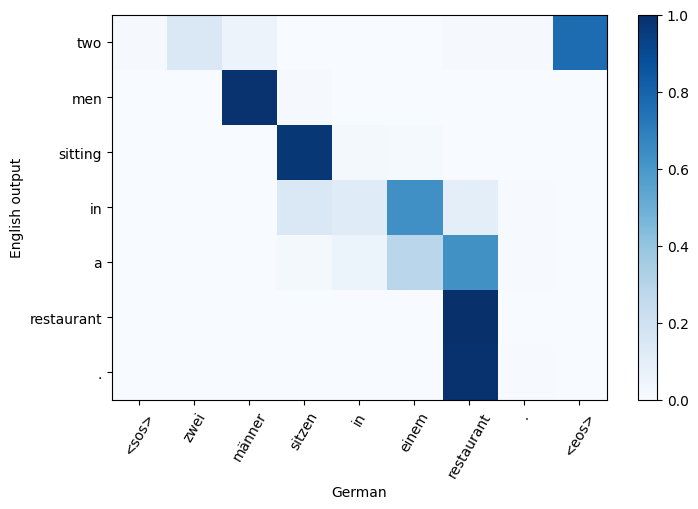

Ein älterer Mann sitzt in einem Stuhl und isst ein paar Snacks. -> an older man sitting sitting a chair and a pair of a .


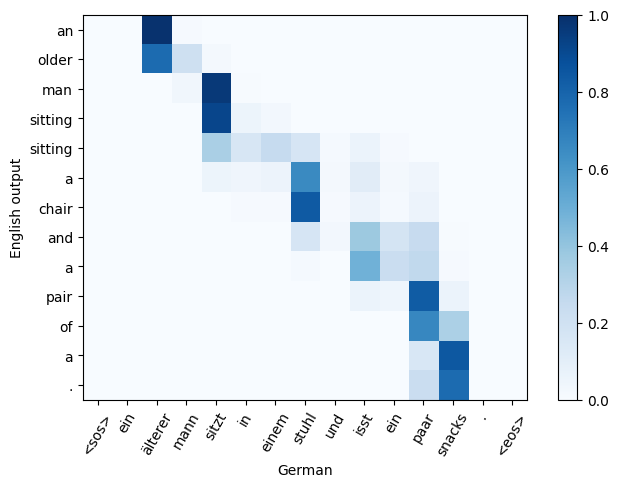

In [9]:
def plot_attention(text):
    words, matrix = greedy_translate(attention_model, text)
    src_tokens = ["<sos>"] + tokenize(text) + ["<eos>"]
    plt.figure(figsize=(8, 5))
    plt.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    plt.xticks(range(len(src_tokens)), src_tokens, rotation=60)
    plt.yticks(range(len(words)), words)
    plt.xlabel("German"); plt.ylabel("English output"); plt.colorbar(); plt.show()

success = next(i for i in range(len(att)) if att[i] == references[i])
for i in [success, examples["FAILURE"]]:
    print(eval_pairs[i][0], "->", att[i])
    plot_attention(eval_pairs[i][0])

**Exercise 6.**

- **Success** ("Zwei Männer sitzen in einem Restaurant."): it is almost a clean diagonal. *men* → "männer", *sitting* → "sitzen", *restaurant* → "restaurant". *two* looks mostly at `<eos>`, and the weight for "in a" is spread over "in / einem".
- **Failure** ("Ein älterer Mann sitzt …"): *older* → "älterer" and *chair* → "stuhl" are good, but *man* looks at "sitzt", not "mann". *sitting* is produced twice because attention stays near "sitzt": the decoder does not remember which words it already used. *pair* attends to "paar", which explains the literal mistake.
- **Compared with the tweet classifier:** the classifier computes attention **once** for the whole sentence (one label). This decoder recomputes it **for every output word**, so we get a full matrix.
- **Limitation:** each encoder output also contains information about the words before it, and high weight does not prove cause. So the map is a hint, not a true word alignment.